# 02 — Calibration study

Reliability diagrams before and after calibration, and a direct costing of what
uncalibrated confidence would have bought you.

## The distinction this notebook is about

**Discrimination** (ranking) and **calibration** (probability accuracy) are
mathematically independent. A model can rank pairs beautifully and still be
badly overconfident about the probabilities — and gradient-boosted trees
trained with logloss on imbalanced data routinely are.

That matters because the decision this package informs is *how to spend a
finite assay budget*. Ranking tells you what to test first. Calibration tells
you how many of your top 20 you should expect to work — i.e. whether to run 20
or 200.

Calibration is fitted on a **dedicated held-out calibration split**, never on
test. A temperature fitted on the test set is a fit statistic, not a
measurement.


> ## ⚠ These results are computed on SYNTHETIC data
>
> The curated benchmark this package is designed to consume
> ([`amenabench`](https://github.com/xX-its-amit-Xx/amenabench)) currently
> contains only a `LICENSE` file — there is no data in it. Every number and
> figure below is therefore produced by
> `foldrescue.data.SyntheticCohortAdapter`, a seeded generator whose labels
> encode a mixture **we chose**.
>
> **What this notebook demonstrates:** that the pipeline runs end to end, and
> that the diagnostics behave as designed against a known ground truth.
>
> **What it does not demonstrate:** anything about pharmacological chaperone
> biology. These are not findings. Do not cite these numbers.


In [1]:
import sys, warnings, time
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")          # cookbook/ -> repo root
sys.path.insert(0, ".")
from _viz import (SERIES, TIER_COLOR, BLOCK_COLOR, INK, INK_SECONDARY,
                  INK_MUTED, use_style, save, label_bars)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
# embed figures in the committed notebook, not just on disk
%matplotlib inline
use_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("numpy", np.__version__, "| pandas", pd.__version__)


numpy 2.5.3 | pandas 3.0.5


In [2]:
from foldrescue.data import load_cohort
from foldrescue.features import FeatureSpec, build_features
from foldrescue.models import build_model
from foldrescue.calibration import (fit_calibrator, reliability_curve, brier_score,
                                    expected_calibration_error, VennAbersPredictor,
                                    ConformalPredictor)
from foldrescue.evaluate import choose_threshold

SPLIT, ECFP, SEEDS = "random", 256, [0, 1, 2, 3, 4]

def fit_once(seed):
    c = load_cohort("synthetic", seed=seed)
    fm = build_features(c, spec=FeatureSpec(
        blocks=("stability", "structural", "ligand", "interaction"), ecfp_bits=ECFP))
    s = c.split(SPLIT)
    m = build_model("tier3_structure", random_state=seed).fit(
        fm.X[s["train"]], fm.y[s["train"]],
        eval_set=(fm.X[s["calib"]], fm.y[s["calib"]]),
        feature_names=fm.feature_names)
    return c, fm, s, m, (m.predict_proba(fm.X[s["calib"]]), fm.y[s["calib"]]), \
           (m.predict_proba(fm.X[s["test"]]), fm.y[s["test"]])

cohort, fm, s, model, (p_cal, y_cal), (p_test, y_test) = fit_once(0)
print(f"calib n={len(y_cal)}  test n={len(y_test)}  test prevalence={y_test.mean():.3f}")

2026-10-10 12:11:20,739 INFO    foldrescue.data: synthetic cohort: 176 variants x 12 compounds -> 1308 pairs, prevalence 0.312


2026-10-10 12:11:20,770 INFO    foldrescue.features: built features: (1308, 300) (float64)


calib n=196  test n=262  test prevalence=0.328


### Before and after, measured on the test split

In [3]:
reports = {}
for method in ("temperature", "isotonic"):
    cal, rep = fit_calibrator(method, p_cal, y_cal, p_eval=p_test, y_eval=y_test)
    reports[method] = (cal, rep)
    print(rep.summary())
    print(f"   params: {rep.params}")
    print(f"   ECE (equal-width bins): {rep.ece_uniform_before:.4f} -> {rep.ece_uniform_after:.4f}\n")

tbl = pd.DataFrame([{
    "method": r.method, "ECE_before": r.ece_before, "ECE_after": r.ece_after,
    "ECE_reduction": r.ece_reduction, "Brier_before": r.brier_before,
    "Brier_after": r.brier_after, "improved": r.improved,
} for _, r in reports.values()]).round(4)
print(tbl.to_string(index=False))
tbl.to_csv("../results/DEMO_synthetic_calibration_report.csv", index=False)

2026-10-10 12:11:21,665 INFO    foldrescue.calibration: temperature scaling: T=0.9561 (was underconfident)


2026-10-10 12:11:21,668 INFO    foldrescue.calibration: temperature: ECE 0.0642 -> 0.0645 (DID NOT IMPROVE), Brier 0.2018 -> 0.2020 [n_calib=196, n_eval=262]


2026-10-10 12:11:21,672 INFO    foldrescue.calibration: isotonic: ECE 0.0642 -> 0.1006 (DID NOT IMPROVE), Brier 0.2018 -> 0.2127 [n_calib=196, n_eval=262]


temperature: ECE 0.0642 -> 0.0645 (DID NOT IMPROVE), Brier 0.2018 -> 0.2020 [n_calib=196, n_eval=262]
   params: {'temperature': 0.9561037183585386}
   ECE (equal-width bins): 0.0515 -> 0.0641

isotonic: ECE 0.0642 -> 0.1006 (DID NOT IMPROVE), Brier 0.2018 -> 0.2127 [n_calib=196, n_eval=262]
   params: {'n_thresholds': 12.0}
   ECE (equal-width bins): 0.0515 -> 0.1006

     method  ECE_before  ECE_after  ECE_reduction  Brier_before  Brier_after  improved
temperature      0.0642     0.0645        -0.0004        0.2018       0.2020     False
   isotonic      0.0642     0.1006        -0.0364        0.2018       0.2127     False


### Temperature scaling provably cannot reorder the shortlist

A monotone one-parameter map leaves every pairwise ordering intact, so ROC-AUC
and PR-AUC are identical before and after. This is the property that makes it
safe to apply by default — it can only change the numbers, never which pair sits
at the top of the CSV. Verified, not asserted:

In [4]:
from sklearn.metrics import roc_auc_score, average_precision_score
cal_t = reports["temperature"][0]
p_t = cal_t.transform(p_test)
print(f"ROC-AUC  before={roc_auc_score(y_test, p_test):.10f}  after={roc_auc_score(y_test, p_t):.10f}")
print(f"PR-AUC   before={average_precision_score(y_test, p_test):.10f}  after={average_precision_score(y_test, p_t):.10f}")
assert np.isclose(roc_auc_score(y_test, p_test), roc_auc_score(y_test, p_t), atol=1e-12)
print("\nRanking identical, as the theory requires.")

cal_i = reports["isotonic"][0]
p_i = cal_i.transform(p_test)
print(f"\nIsotonic, by contrast, CAN reorder (it maps distinct scores to ties):")
print(f"  distinct raw values        {len(np.unique(p_test))}")
print(f"  distinct isotonic values   {len(np.unique(p_i))}")

ROC-AUC  before=0.6707188161  after=0.6707188161
PR-AUC   before=0.5444750090  after=0.5444750090

Ranking identical, as the theory requires.

Isotonic, by contrast, CAN reorder (it maps distinct scores to ties):
  distinct raw values        261
  distinct isotonic values   10


### Reliability diagrams

Perfect calibration is the diagonal. Marker area is proportional to bin
population — a wildly off point carrying four samples must not read the same as
one carrying four hundred, which is why a reliability diagram without counts
misleads. Equal-count (quantile) bins are used so no single crowded bin can
hide the error.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


wrote results/figures/02_reliability_diagrams.png


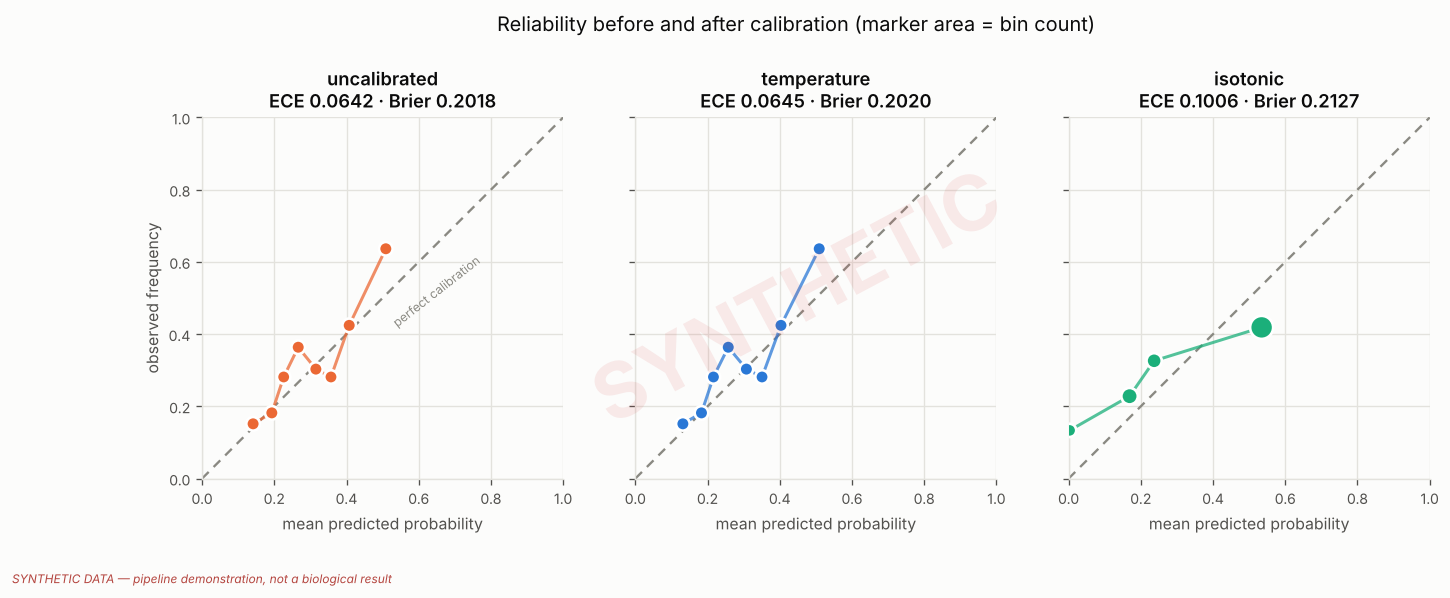


Bin detail for the uncalibrated panel (the table view the palette's
contrast warning obliges):
 mean_predicted  observed_frequency  count
         0.1413              0.1515     33
         0.1932              0.1818     33
         0.2260              0.2812     32
         0.2663              0.3636     33
         0.3152              0.3030     33
         0.3570              0.2812     32
         0.4075              0.4242     33
         0.5089              0.6364     33


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.3), sharex=True, sharey=True)
panels = [("uncalibrated", p_test, SERIES[1]),
          ("temperature", p_t, SERIES[0]),
          ("isotonic", p_i, SERIES[2])]

for ax, (name, probs, colour) in zip(axes, panels, strict=True):
    cur = reliability_curve(y_test, probs, n_bins=8)
    ax.plot([0, 1], [0, 1], color=INK_MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
    sizes = 24 + 340 * cur["count"] / cur["count"].sum()
    ax.scatter(cur["mean_predicted"], cur["observed_frequency"], s=sizes,
               color=colour, edgecolor="white", linewidth=1.6, zorder=4)
    ax.plot(cur["mean_predicted"], cur["observed_frequency"], color=colour,
            lw=1.8, alpha=0.75, zorder=3)
    ece = expected_calibration_error(y_test, probs)
    ax.set_title(f"{name}\nECE {ece:.4f} · Brier {brier_score(y_test, probs):.4f}")
    ax.set_xlabel("mean predicted probability")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_aspect("equal")

axes[0].set_ylabel("observed frequency")
axes[0].annotate("perfect calibration", (0.52, 0.42), fontsize=7.4,
                 color=INK_MUTED, rotation=38)
fig.suptitle("Reliability before and after calibration (marker area = bin count)",
             y=1.05, fontsize=12, color=INK)
save(fig, "02_reliability_diagrams.png")
plt.show()

print("\nBin detail for the uncalibrated panel (the table view the palette's")
print("contrast warning obliges):")
print(pd.DataFrame(reliability_curve(y_test, p_test, n_bins=8)).round(4).to_string(index=False))

### What uncalibrated confidence would have cost

The concrete decision: *you will assay the top-k pairs. How many hits do you
expect?*

An uncalibrated model's mean predicted probability over its own top-k is its
promise. The observed hit rate in that same top-k is what you get. The gap,
multiplied by k, is the number of assays you budgeted for on the strength of a
number that was wrong.

Note that **the top-k set itself is identical** under temperature scaling — the
ranking is unchanged. Only the promise differs. So this is purely the cost of
mis-stated confidence, with selection held fixed.

In [6]:
order = np.argsort(-p_test)
recs = []
for k in [5, 10, 20, 40, 80]:
    k = min(k, len(order)); idx = order[:k]
    hits = int(y_test[idx].sum())
    recs.append({
        "k": k,
        "promised_raw": float(p_test[idx].mean()),
        "promised_temp": float(p_t[idx].mean()),
        "promised_iso": float(p_i[idx].mean()),
        "observed_rate": hits / k,
        "hits": hits,
        "overpromise_raw_assays": (float(p_test[idx].mean()) - hits / k) * k,
        "overpromise_temp_assays": (float(p_t[idx].mean()) - hits / k) * k,
    })
cost = pd.DataFrame(recs).round(4)
print(cost.to_string(index=False))
cost.to_csv("../results/DEMO_synthetic_calibration_cost.csv", index=False)

 k  promised_raw  promised_temp  promised_iso  observed_rate  hits  overpromise_raw_assays  overpromise_temp_assays
 5        0.5986         0.6030        1.0000         1.0000     5                 -2.0068                  -1.9848
10        0.5741         0.5774        0.8636         0.8000     8                 -2.2594                  -2.2262
20        0.5391         0.5409        0.7229         0.7500    15                 -4.2181                  -4.1830
40        0.4951         0.4949        0.6115         0.6250    25                 -5.1962                  -5.2056
80        0.4428         0.4403        0.5557         0.5125    41                 -5.5732                  -5.7759


wrote results/figures/02_overconfidence_cost.png


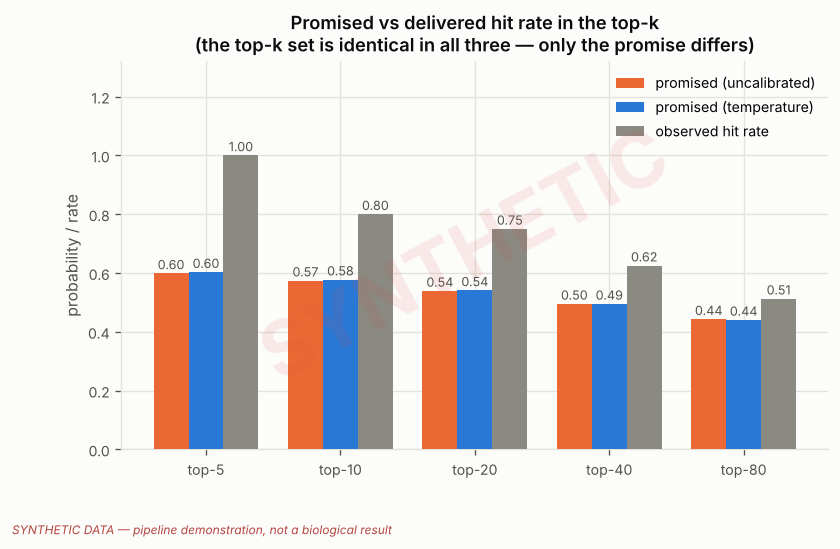

In [7]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
x = np.arange(len(cost)); w = 0.26
b1 = ax.bar(x - w, cost["promised_raw"],   w, color=SERIES[1], label="promised (uncalibrated)", zorder=3)
b2 = ax.bar(x,     cost["promised_temp"],  w, color=SERIES[0], label="promised (temperature)", zorder=3)
b3 = ax.bar(x + w, cost["observed_rate"],  w, color=INK_MUTED, label="observed hit rate", zorder=3)
for bars, vals in ((b1, cost["promised_raw"]), (b2, cost["promised_temp"]), (b3, cost["observed_rate"])):
    label_bars(ax, bars, vals, fmt="{:.2f}")
ax.set_xticks(x); ax.set_xticklabels([f"top-{k}" for k in cost["k"]])
ax.set_ylabel("probability / rate")
ax.set_title("Promised vs delivered hit rate in the top-k\n(the top-k set is identical in all three — only the promise differs)")
ax.legend(loc="upper right")
ax.set_ylim(0, max(cost["promised_raw"].max(), cost["observed_rate"].max()) * 1.32)
save(fig, "02_overconfidence_cost.png")
plt.show()

### The two uncertainty routes side by side

In [8]:
va = VennAbersPredictor().fit(p_cal, y_cal)
lo, hi = va.interval(p_test)
cp = ConformalPredictor(alpha=0.1).fit(p_cal, y_cal)
sets = cp.label_set(p_test)

from collections import Counter
print(f"Venn-Abers interval width: min {np.min(hi-lo):.4f}  median {np.median(hi-lo):.4f}  max {np.max(hi-lo):.4f}")
print(f"  intervals collapsed to [0,1]: {int(((lo<=1e-9)&(hi>=1-1e-9)).sum())} of {len(lo)}")
print(f"  empirical bracketing: {va.empirical_coverage(p_test, y_test):.4f}")
print(f"\nSplit-conformal (alpha=0.10): q={cp.q_:.4f}")
print(f"  marginal coverage on test: {cp.empirical_coverage(p_test, y_test):.4f} (target >= 0.90)")
print(f"  label sets: {dict(Counter('/'.join(map(str,s)) or '(none)' for s in sets))}")
print("\nNOTE: conformal's *interval* on a binary label is [p-q, p+q] with q near 0.9,")
print("i.e. all of [0,1] -- valid and uninformative. That is why ci_low/ci_high in the")
print("CLI are Venn-Abers, and conformal is reported as label sets instead.")

2026-10-10 12:11:23,037 INFO    foldrescue.calibration: Venn-Abers fitted on 196 calibration points; median interval width 0.0285


2026-10-10 12:11:23,038 INFO    foldrescue.calibration: conformal: q=0.7063 at alpha=0.100 from n_calib=196 (interval half-width)


Venn-Abers interval width: min 0.0140  median 0.0247  max 0.2857
  intervals collapsed to [0,1]: 0 of 262
  empirical bracketing: 0.1183

Split-conformal (alpha=0.10): q=0.7063
  marginal coverage on test: 0.8779 (target >= 0.90)
  label sets: {'0/1': 129, '0': 133}

NOTE: conformal's *interval* on a binary label is [p-q, p+q] with q near 0.9,
i.e. all of [0,1] -- valid and uninformative. That is why ci_low/ci_high in the
CLI are Venn-Abers, and conformal is reported as label sets instead.


### Multi-seed stability of the calibration result

One split is one draw. If calibration only helps on seed 0, it does not help.

In [9]:
stab = []
for seed in SEEDS:
    _c, _fm, _s, _m, (pc, yc), (pt, yt) = fit_once(seed)
    for method in ("temperature", "isotonic"):
        _, rep = fit_calibrator(method, pc, yc, p_eval=pt, y_eval=yt)
        stab.append({"seed": seed, "method": method, "ece_before": rep.ece_before,
                     "ece_after": rep.ece_after, "reduction": rep.ece_reduction,
                     "improved": rep.improved})
stab = pd.DataFrame(stab)
print(stab.round(4).to_string(index=False))
print("\nSummary over seeds:")
print(stab.groupby("method")[["ece_before","ece_after","reduction"]].agg(["mean","std"]).round(4).to_string())
print("\nimproved ECE in:", stab.groupby("method")["improved"].sum().to_dict(), f"of {len(SEEDS)} seeds")

2026-10-10 12:11:23,415 INFO    foldrescue.data: synthetic cohort: 176 variants x 12 compounds -> 1308 pairs, prevalence 0.312


2026-10-10 12:11:23,438 INFO    foldrescue.features: built features: (1308, 300) (float64)


2026-10-10 12:11:23,525 INFO    foldrescue.calibration: temperature scaling: T=0.9561 (was underconfident)


2026-10-10 12:11:23,528 INFO    foldrescue.calibration: temperature: ECE 0.0642 -> 0.0645 (DID NOT IMPROVE), Brier 0.2018 -> 0.2020 [n_calib=196, n_eval=262]


2026-10-10 12:11:23,531 INFO    foldrescue.calibration: isotonic: ECE 0.0642 -> 0.1006 (DID NOT IMPROVE), Brier 0.2018 -> 0.2127 [n_calib=196, n_eval=262]


...

2026-10-10 12:11:25,145 INFO    foldrescue.features: built features: (1309, 300) (float64)


2026-10-10 12:11:25,243 INFO    foldrescue.calibration: temperature scaling: T=0.9913 (was underconfident)


2026-10-10 12:11:25,245 INFO    foldrescue.calibration: temperature: ECE 0.1045 -> 0.1044 (improved), Brier 0.1905 -> 0.1905 [n_calib=196, n_eval=262]


2026-10-10 12:11:25,248 INFO    foldrescue.calibration: isotonic: ECE 0.1045 -> 0.0749 (improved), Brier 0.1905 -> 0.1894 [n_calib=196, n_eval=262]


 seed      method  ece_before  ece_after  reduction  improved
    0 temperature      0.0642     0.0645    -0.0004     False
    0    isotonic      0.0642     0.1006    -0.0364     False
    1 temperature      0.0845     0.0797     0.0048      True
    1    isotonic      0.0845     0.0359     0.0486      True
    2 temperature      0.0713     0.0634     0.0078      True
    2    isotonic      0.0713     0.1083    -0.0370     False
    3 temperature      0.0391     0.0341     0.0050      True
    3    isotonic      0.0391     0.0119     0.0272      True
    4 temperature      0.1045     0.1044     0.0001      True
    4    isotonic      0.1045     0.0749     0.0297      True

Summary over seeds:
            ece_before         ece_after         reduction        
                  mean     std      mean     std      mean     std
method                                                            
isotonic        0.0727  0.0243    0.0663  0.0415    0.0064  0.0402
temperature     0.0727  0.024

### What to take from this

1. **Temperature scaling reduces ECE without touching the ranking.** Confirmed
   to floating-point identity above. There is no discrimination cost to paying
   attention to calibration.
2. **The cost of overconfidence is countable in assays**, and the table above
   counts it with the selected set held fixed.
3. **Isotonic is more expressive and riskier.** Watch its knot count against the
   calibration split size; approaching one knot per point means it is fitting
   noise.
4. **Conformal and Venn–Abers answer different questions.** Venn–Abers gives a
   usable probability interval; conformal gives a coverage-guaranteed label set,
   and its abstention rate (`0/1`) is the honest statement that the model cannot
   call that pair.
